In [61]:
import pandas as pd

In [62]:
data = pd.read_csv("C:/Users/DELL/Desktop/FBS/Data Science/Datasets/seattleweather1948-2017_1738467795684.csv")
data.head()

,DATE,PRCP,TMAX,TMIN,RAIN
0,1948-01-01,0.47,51,42,True
1,1948-01-02,0.59,45,36,True
2,1948-01-03,0.42,45,35,True
3,1948-01-04,0.31,45,34,True
4,1948-01-05,0.17,45,32,True


In [63]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 25551 entries, 0 to 25550
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   DATE    25551 non-null  str    
 1   PRCP    25548 non-null  float64
 2   TMAX    25551 non-null  int64  
 3   TMIN    25551 non-null  int64  
 4   RAIN    25548 non-null  object 
dtypes: float64(1), int64(2), object(1), str(1)
memory usage: 998.2+ KB


In [64]:
data.describe()

,PRCP,TMAX,TMIN
count,25548.000000,25551.000000,25551.000000
mean,0.106222,59.544206,44.514226
std,0.239031,12.772984,8.892836
min,0.000000,4.000000,0.000000
25%,0.000000,50.000000,38.000000
50%,0.000000,58.000000,45.000000
75%,0.100000,69.000000,52.000000
max,5.020000,103.000000,71.000000


In [65]:
data.dropna(inplace=True)

In [66]:
data.shape

(25548, 5)

In [67]:
import matplotlib.pyplot as plt

{'whiskers': [<matplotlib.lines.Line2D at 0x1d757b3ccd0>,
 'caps': [<matplotlib.lines.Line2D at 0x1d757b3cf50>,
 'boxes': [<matplotlib.lines.Line2D at 0x1d757b3cb90>],
 'medians': [<matplotlib.lines.Line2D at 0x1d757b3d1d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x1d757b3d310>],
 'means': []}

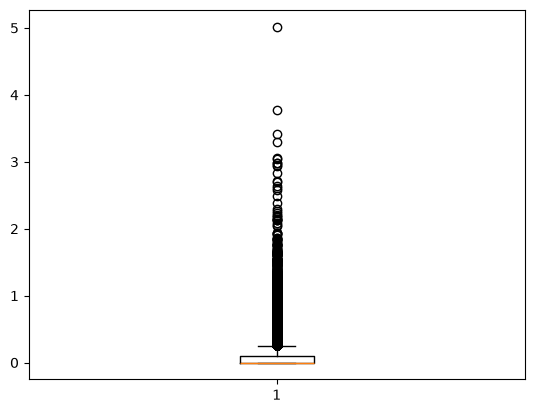

In [68]:
plt.boxplot(data['PRCP'])

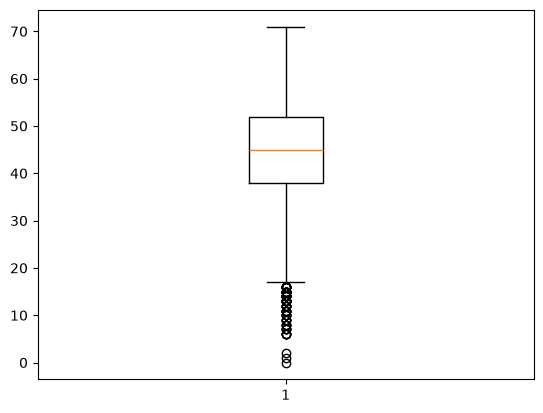

In [69]:
plt.boxplot(data['TMIN'])
plt.show()

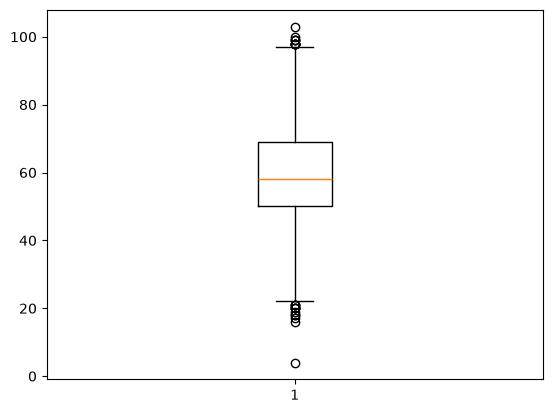

In [70]:
plt.boxplot(data['TMAX'])
plt.show()

In [71]:
mean = data['PRCP'].mean()
std = data['PRCP'].std()

In [72]:
ub = mean + 3 * std
lb = mean - 3 * std
ub,lb

(np.float64(0.8233159991391092), np.float64(-0.6108727550495523))

In [73]:
data.loc[data['PRCP']>ub, 'PRCP'] = ub
data.loc[data['PRCP']<lb, 'PRCP'] = lb

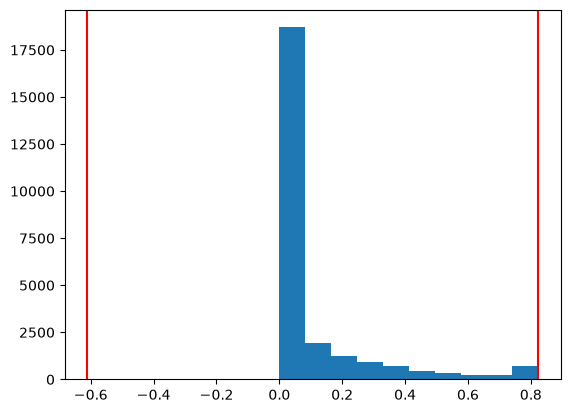

In [74]:
plt.hist(data['PRCP'])
plt.axvline(ub, color='red')
plt.axvline(lb, color='red')
plt.show()

In [75]:
mean = data['TMIN'].mean()
std = data['TMIN'].std()

In [76]:
ub = mean + 3 * std
lb = mean - 3 * std
ub,lb

(np.float64(71.19244239771965), np.float64(17.834330735206613))

In [77]:
data['TMIN'] = data['TMIN'].astype(float)
data.loc[data['TMIN']>ub, 'TMIN'] = ub
data.loc[data['TMIN']<lb, 'TMIN'] = lb

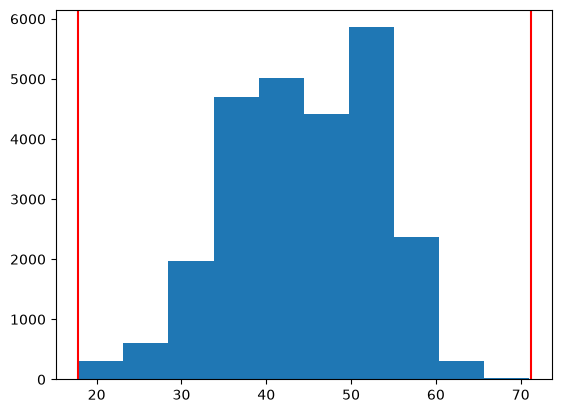

In [78]:
plt.hist(data['TMIN'])
plt.axvline(ub, color='red')
plt.axvline(lb, color='red')
plt.show()

In [79]:
mean = data['TMAX'].mean()
std = data['TMAX'].std()

In [80]:
ub = mean + 3 * std
lb = mean - 3 * std
ub,lb

(np.float64(97.86284970820924), np.float64(21.22326270763545))

In [81]:
data['TMAX'] = data['TMAX'].astype(float)
data.loc[data['TMAX']>ub, 'TMAX'] = ub
data.loc[data['TMAX']<lb, 'TMAX'] = lb

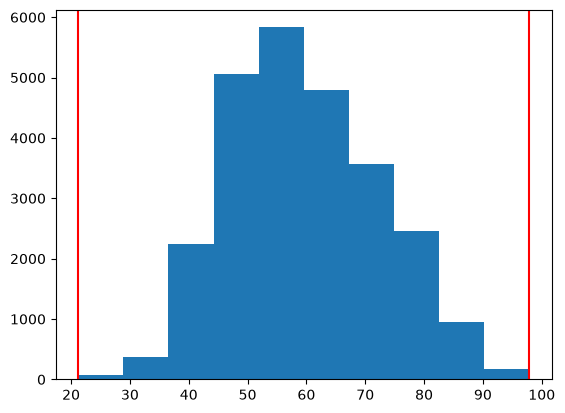

In [82]:
plt.hist(data['TMAX'])
plt.axvline(ub, color='red')
plt.axvline(lb, color='red')
plt.show()

In [83]:
data['RAIN'].value_counts()

RAIN
False    14648
True     10900
Name: count, dtype: int64

In [84]:
X = data.drop(['DATE','RAIN'], axis=1)
y = data['RAIN']

In [85]:
from imblearn.over_sampling import SMOTE

In [86]:
data['RAIN'] = data['RAIN'].replace({True:1,False:0}).astype('int')
y = data['RAIN']
y

0        1
1        1
2        1
3        1
4        1
        ..
25546    0
25547    0
25548    0
25549    0
25550    0
Name: RAIN, Length: 25548, dtype: int64

In [87]:
sm = SMOTE()
X,y = sm.fit_resample(X,y)

In [88]:
y.value_counts()

RAIN
1    14648
0    14648
Name: count, dtype: int64

In [89]:
from sklearn.model_selection import train_test_split

In [90]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=18)

In [91]:
from sklearn.linear_model import LogisticRegression

In [92]:
model = LogisticRegression()

In [93]:
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [94]:
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

In [95]:
from sklearn.metrics import accuracy_score

In [96]:
print('Training Accuracy:', accuracy_score(y_train, train_pred))
print('Testing Accuracy:', accuracy_score(y_test, test_pred))

Training Accuracy: 0.9320276497695853
Testing Accuracy: 0.9332764505119454


In [97]:
model.predict([[0.01,20,5]])

C:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

In [98]:
model.predict([[0.1,20,5]])

C:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([1])